# Experiment 6: Feature Scaling and PCA

This notebook compares MinMax normalization and standardization for five Titanic features, then uses PCA to reduce them to two components. The PCA scatter plot colors passengers by survival outcome.

The Titanic CSV is loaded from a public raw dataset so the notebook can run without a separate upload.

## Load and prepare the Titanic data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler,StandardScaler
from sklearn.decomposition import PCA
df = pd.read_csv("https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv")


## Normalize and standardize the features

In [2]:
df["Age"] = df["Age"].fillna(df["Age"].median())
features=df[['Pclass','Age','SibSp','Parch','Fare']]
print("original data:\n",features.head())
minmax=MinMaxScaler()
normalized = minmax.fit_transform(features)
print("\nNormalised Data(first 5 rows): \n",normalized[:5].round(3))
print("\nNormalised Range: ",normalized.min(), "to", normalized.max())
scaler = StandardScaler()
standardized = scaler.fit_transform(features)
print("\nStandardised Data(first 5 rows): \n",standardized[:5].round(3))


original data:
    Pclass   Age  SibSp  Parch     Fare
0       3  22.0      1      0   7.2500
1       1  38.0      1      0  71.2833
2       3  26.0      0      0   7.9250
3       1  35.0      1      0  53.1000
4       3  35.0      0      0   8.0500

Normalised Data(first 5 rows): 
 [[1.    0.271 0.125 0.    0.014]
 [0.    0.472 0.125 0.    0.139]
 [1.    0.321 0.    0.    0.015]
 [0.    0.435 0.125 0.    0.104]
 [1.    0.435 0.    0.    0.016]]

Normalised Range:  0.0 to 1.0

Standardised Data(first 5 rows): 
 [[ 0.827 -0.566  0.433 -0.474 -0.502]
 [-1.566  0.664  0.433 -0.474  0.787]
 [ 0.827 -0.258 -0.475 -0.474 -0.489]
 [-1.566  0.433  0.433 -0.474  0.421]
 [ 0.827  0.433 -0.475 -0.474 -0.486]]


## Reduce dimensions with PCA

In [3]:
print("\nStandardised Mean: ",standardized.mean().round(4),"std: ",standardized.std().round(4))
pca = PCA(n_components=2)
principal_components = pca.fit_transform(standardized)
print("Shape before PCA:", standardized.shape, "| Shape after PCA:", principal_components.shape)
print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))
print("Total variance captured by 2 components:", round((sum(pca.explained_variance_ratio_)*100), 2),"%")



Standardised Mean:  0.0 std:  1.0
Shape before PCA: (891, 5) | Shape after PCA: (891, 2)
Explained variance ratio: [0.3396 0.3252]
Total variance captured by 2 components: 66.48 %


## Plot the principal components

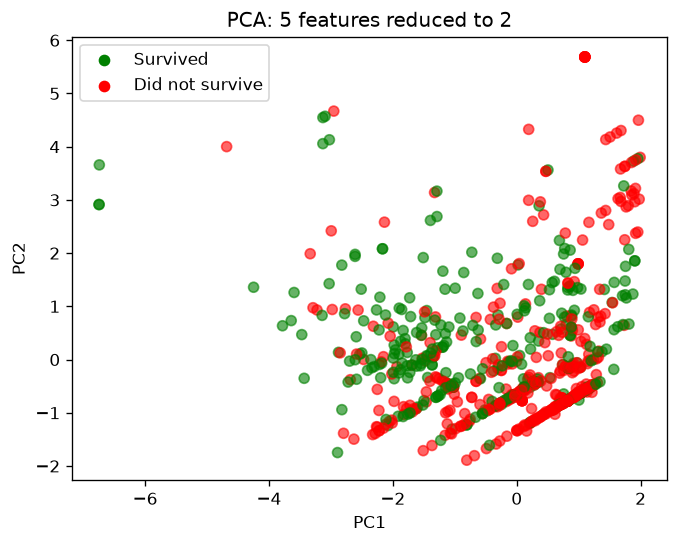

In [4]:
colors = df["Survived"].map({1: "green", 0: "red"})
plt.scatter(principal_components[:, 0], principal_components[:, 1], c=colors, alpha=0.6)
plt.scatter([], [], c="green", label="Survived")
plt.scatter([], [], c="red", label="Did not survive")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA: 5 features reduced to 2")
plt.legend()
plt.show()